# 01 — Exploratory Data Analysis
**Project:** California Property Close Price Prediction (IDX Exchange, team ds76)  
**Week 2 deliverable:** basic EDA on CRMLS sold listings.

Scope (per task doc): `PropertyType == "Residential"` and `PropertySubType == "SingleFamilyResidence"`.  
Target variable: **`ClosePrice`**. Data: CRMLSSold Oct 2025 – May 2026 (8 months).

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Load all months

In [2]:
files = sorted(glob.glob("CRMLSSold*.csv"))
frames = []
for f in files:
    d = pd.read_csv(f, low_memory=False)
    d["SourceMonth"] = f[len("CRMLSSold"):-len(".csv")]   # e.g. 202510
    frames.append(d)
raw = pd.concat(frames, ignore_index=True)
print(f"{len(files)} files, {raw.shape[0]:,} rows, {raw.shape[1]} columns")
raw.groupby("SourceMonth").size().rename("rows").to_frame().T

8 files, 166,725 rows, 79 columns


SourceMonth,202510,202511,202512,202601,202602,202603,202604,202605
rows,23233,19088,20538,16487,18124,22583,23412,23260


In [3]:
raw["PropertyType"].value_counts().to_frame("rows")

,rows
PropertyType,
Residential,111518
ResidentialLease,39087
Land,5269
ResidentialIncome,4597
ManufacturedInPark,4266
CommercialSale,1061
CommercialLease,841
BusinessOpportunity,86


## 2. Filter to single-family residential

In [4]:
df = raw[(raw["PropertyType"] == "Residential") &
         (raw["PropertySubType"] == "SingleFamilyResidence")].copy()
print(f"SFR rows: {len(df):,} ({len(df)/len(raw):.1%} of all rows)")

dups = df["ListingKey"].duplicated().sum()
print(f"Duplicate ListingKey rows: {dups}")
df = df.drop_duplicates("ListingKey", keep="last")

for c in ["CloseDate", "ListingContractDate", "PurchaseContractDate"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")
df["CloseMonth"] = df["CloseDate"].dt.to_period("M")
print(f"After dedupe: {len(df):,} rows")

SFR rows: 83,495 (50.1% of all rows)
Duplicate ListingKey rows: 60
After dedupe: 83,435 rows


## 3. Missing values

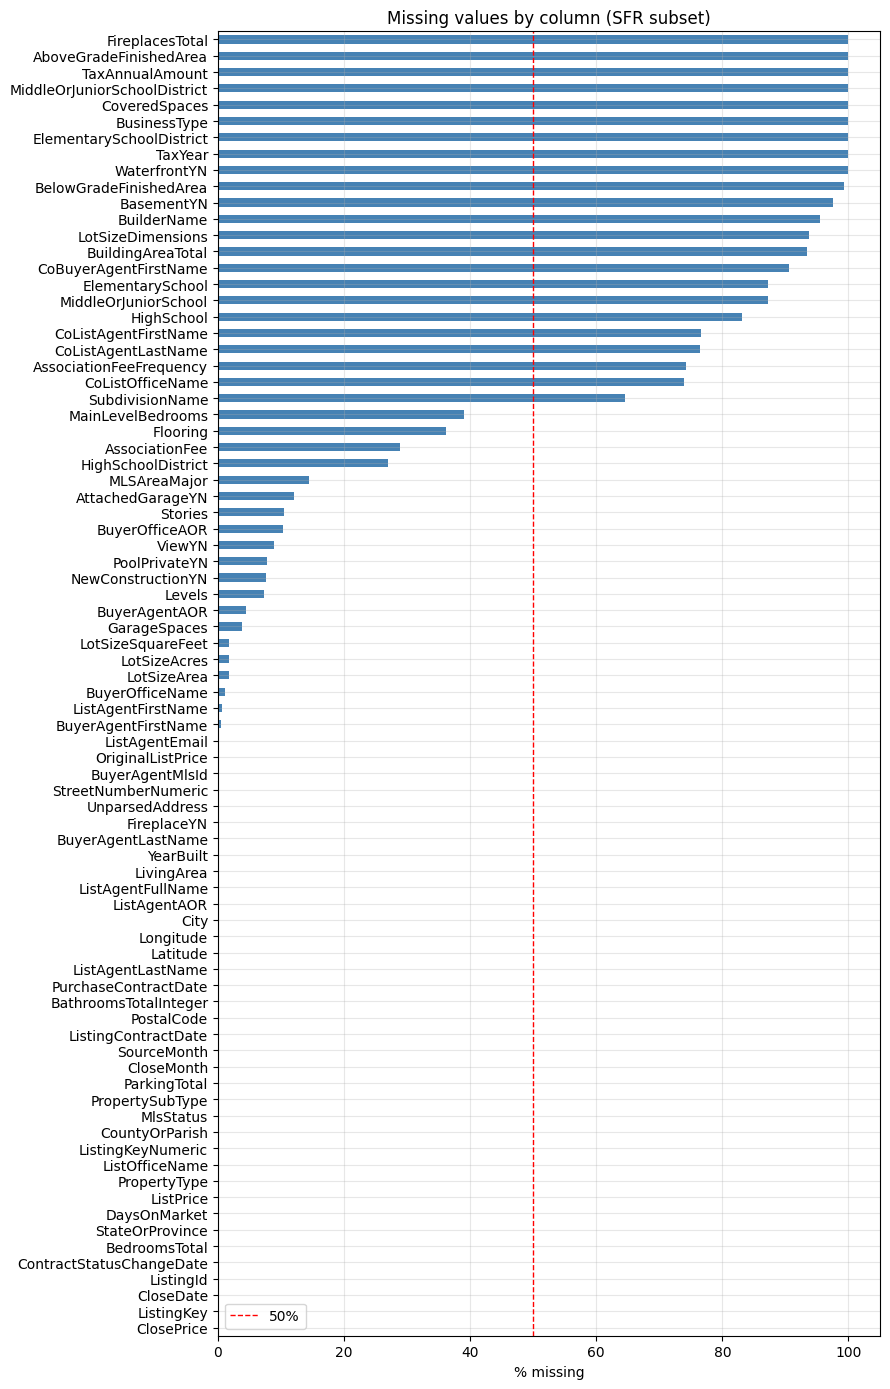

Columns >90% missing (likely drop):
['TaxYear', 'ElementarySchoolDistrict', 'BusinessType', 'CoveredSpaces', 'MiddleOrJuniorSchoolDistrict', 'TaxAnnualAmount', 'AboveGradeFinishedArea', 'FireplacesTotal', 'WaterfrontYN', 'BelowGradeFinishedArea', 'BasementYN', 'BuilderName', 'LotSizeDimensions', 'BuildingAreaTotal', 'CoBuyerAgentFirstName']


In [5]:
miss = df.isna().mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(9, 14))
miss.sort_values().plot.barh(ax=ax, color="steelblue")
ax.axvline(50, color="red", ls="--", lw=1, label="50%")
ax.set_xlabel("% missing"); ax.set_title("Missing values by column (SFR subset)")
ax.legend(); plt.tight_layout(); plt.show()

print("Columns >90% missing (likely drop):")
print(list(miss[miss > 90].index))

## 4. Summary statistics of key numeric features

In [ ]:
key = ["ClosePrice", "ListPrice", "OriginalListPrice", "LivingArea", "BedroomsTotal",
       "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt", "DaysOnMarket",
       "GarageSpaces", "ParkingTotal", "AssociationFee"]
df[key].describe(percentiles=[.01, .25, .5, .75, .99]).T

,count,mean,std,min,1%,25%,50%,75%,99%,max
ClosePrice,"83,435.00","1,339,490.96","7,666,771.49",1.75,"230,000.00","620,000.00","890,000.00","1,415,000.00","6,495,000.00","989,500,000.00"
ListPrice,"83,435.00","1,265,168.57","1,540,319.51","8,000.00","240,000.00","624,999.00","890,000.00","1,399,000.00","6,500,000.00","75,000,000.00"
OriginalListPrice,"83,259.00","1,377,374.28","8,243,914.14",0.00,"243,480.00","630,000.00","899,000.00","1,429,000.00","6,995,000.00","1,302,000,000.00"
LivingArea,"83,396.00","2,054.10","1,037.99",0.00,740.00,"1,388.00","1,824.00","2,450.00","5,686.00","31,068.00"
BedroomsTotal,"83,435.00",3.50,0.97,0.00,2.00,3.00,3.00,4.00,6.00,22.00
BathroomsTotalInteger,"83,434.00",2.64,1.13,0.00,1.00,2.00,2.00,3.00,6.00,23.00
LotSizeSquareFeet,"81,993.00","488,355.44","20,482,099.76",0.00,"1,731.92","5,663.00","7,260.00","10,454.00","305,355.63","1,938,942,720.00"
YearBuilt,"83,388.00","1,976.08",27.67,"1,801.00","1,911.00","1,956.00","1,976.00","1,998.00","2,025.00","2,026.00"
DaysOnMarket,"83,435.00",41.90,56.36,-265.00,0.00,8.00,20.00,55.00,259.00,"2,177.00"
GarageSpaces,"80,229.00",2.01,3.59,0.00,0.00,2.00,2.00,2.00,4.00,600.00


## 5. Target: ClosePrice

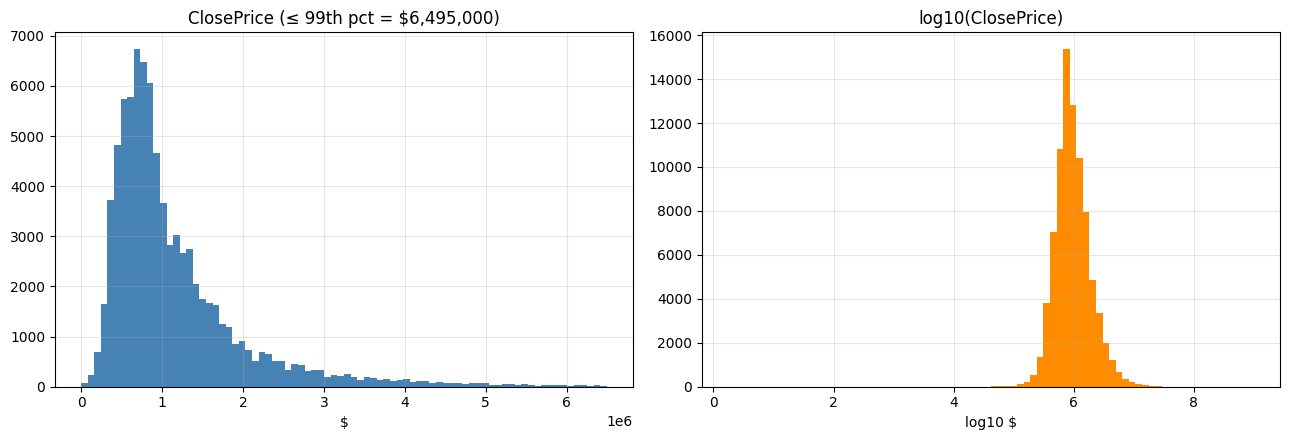

Median $890,000 | Mean $1,339,491 | Skew 94.8
Smallest 5: [1.75, 485.0, 685.0, 8000.0, 8300.0]
Largest 5: [989500000.0, 796000000.0, 768500000.0, 740000000.0, 699000000.0]


In [ ]:
p = df["ClosePrice"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
clip = p.quantile(0.99)
axes[0].hist(p[p <= clip], bins=80, color="steelblue")
axes[0].set_title(f"ClosePrice (≤ 99th pct = ${clip:,.0f})"); axes[0].set_xlabel("$")
axes[1].hist(np.log10(p[p > 0]), bins=80, color="darkorange")
axes[1].set_title("log10(ClosePrice)"); axes[1].set_xlabel("log10 $")
plt.tight_layout(); plt.show()

print(f"Median ${p.median():,.0f} | Mean ${p.mean():,.0f} | Skew {p.skew():.1f}")
print("Smallest 5:", p.nsmallest(5).tolist())
print("Largest 5:", p.nlargest(5).tolist())

## 6. Distributions of key features

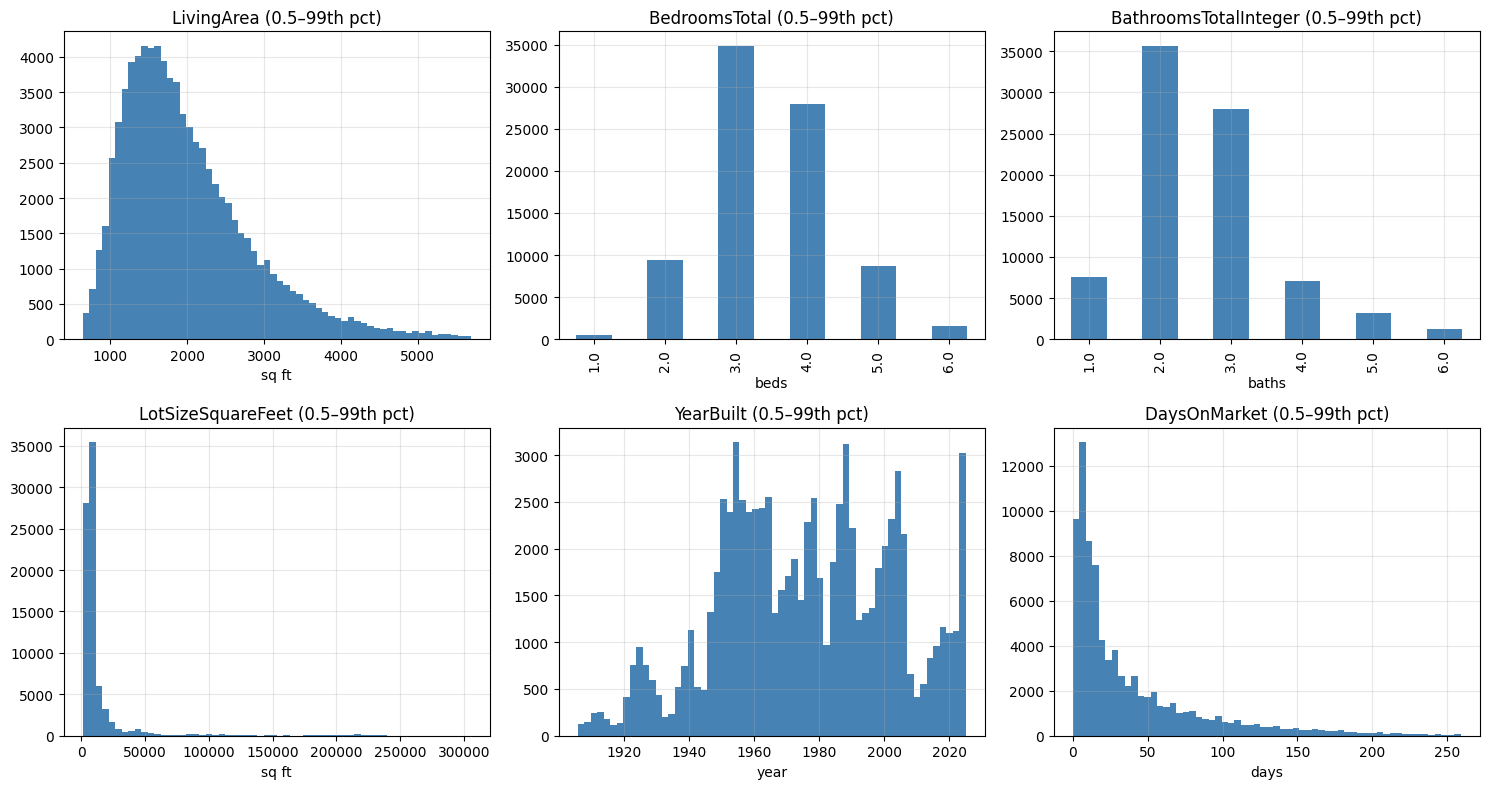

In [8]:
feats = {"LivingArea": "sq ft", "BedroomsTotal": "beds", "BathroomsTotalInteger": "baths",
         "LotSizeSquareFeet": "sq ft", "YearBuilt": "year", "DaysOnMarket": "days"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (c, unit) in zip(axes.ravel(), feats.items()):
    s = df[c].dropna()
    lo, hi = s.quantile([0.005, 0.99])
    s = s[(s >= lo) & (s <= hi)]
    if c in ("BedroomsTotal", "BathroomsTotalInteger"):
        s.value_counts().sort_index().plot.bar(ax=ax, color="steelblue")
    else:
        ax.hist(s, bins=60, color="steelblue")
    ax.set_title(f"{c} (0.5–99th pct)"); ax.set_xlabel(unit)
plt.tight_layout(); plt.show()

## 7. ClosePrice vs features

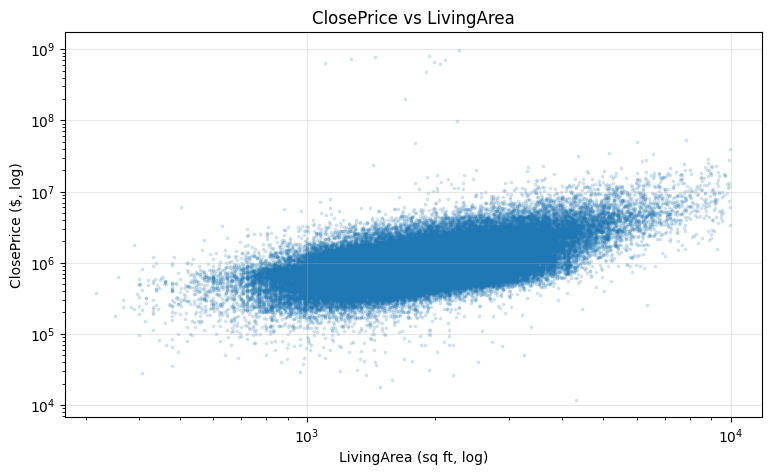

Spearman corr: 0.52


In [9]:
m = df[(df["LivingArea"] > 300) & (df["LivingArea"] < 10000) & (df["ClosePrice"] > 10000)]
fig, ax = plt.subplots()
ax.scatter(m["LivingArea"], m["ClosePrice"], s=3, alpha=0.15)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("LivingArea (sq ft, log)"); ax.set_ylabel("ClosePrice ($, log)")
ax.set_title("ClosePrice vs LivingArea")
plt.show()
print(f"Spearman corr: {m['LivingArea'].rank().corr(m['ClosePrice'].rank()):.2f}")

/sessions/rcw-01rrsrxoo9nwz2nrv6covo5b/tmp/ipykernel_10/3373742393.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sub.loc[sub[c] == g, "ClosePrice"] for g in groups],
/sessions/rcw-01rrsrxoo9nwz2nrv6covo5b/tmp/ipykernel_10/3373742393.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([sub.loc[sub[c] == g, "ClosePrice"] for g in groups],


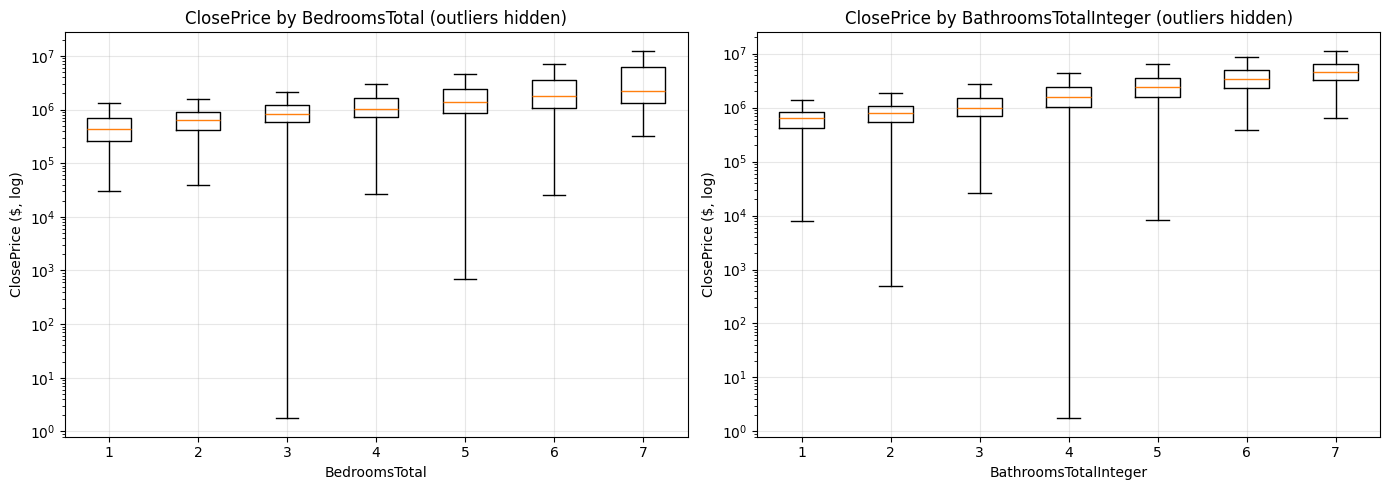

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, c in zip(axes, ["BedroomsTotal", "BathroomsTotalInteger"]):
    sub = df[df[c].between(1, 7)]
    groups = sorted(sub[c].unique())
    ax.boxplot([sub.loc[sub[c] == g, "ClosePrice"] for g in groups],
               labels=[int(g) for g in groups], showfliers=False)
    ax.set_yscale("log"); ax.set_xlabel(c); ax.set_ylabel("ClosePrice ($, log)")
    ax.set_title(f"ClosePrice by {c} (outliers hidden)")
plt.tight_layout(); plt.show()

## 8. Geography

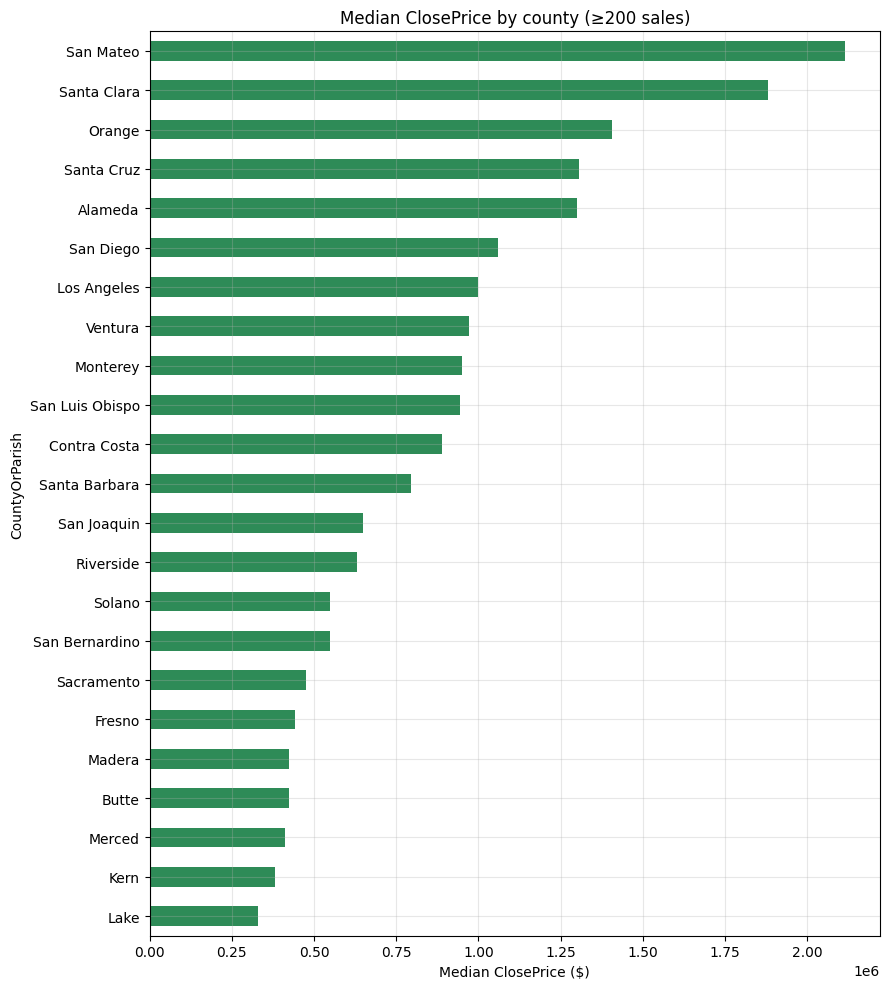

In [11]:
county = (df.groupby("CountyOrParish")["ClosePrice"]
            .agg(sales="size", median_price="median")
            .query("sales >= 200").sort_values("median_price"))
fig, ax = plt.subplots(figsize=(9, 10))
county["median_price"].plot.barh(ax=ax, color="seagreen")
ax.set_xlabel("Median ClosePrice ($)"); ax.set_title("Median ClosePrice by county (≥200 sales)")
plt.tight_layout(); plt.show()

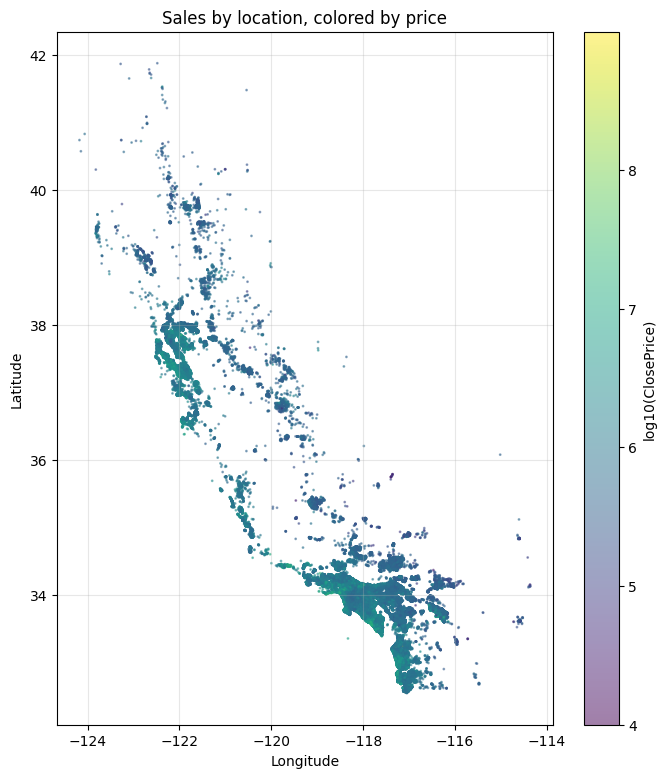

In [12]:
g = df[df["Latitude"].between(32, 42.1) & df["Longitude"].between(-124.5, -114)]
fig, ax = plt.subplots(figsize=(8, 9))
sc = ax.scatter(g["Longitude"], g["Latitude"], c=np.log10(g["ClosePrice"].clip(lower=1e4)),
                s=1, cmap="viridis", alpha=0.5)
plt.colorbar(sc, label="log10(ClosePrice)")
ax.set_title("Sales by location, colored by price"); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.show()

## 9. Over time

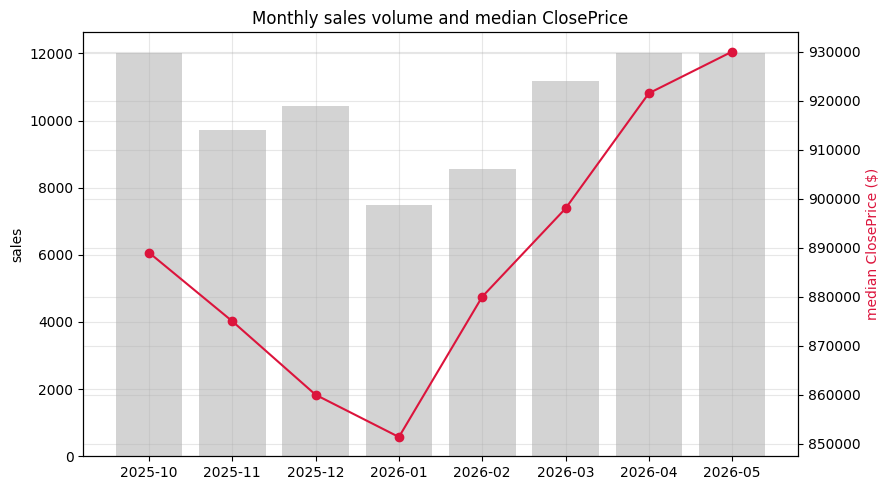

,sales,median_price
CloseMonth,,
2025-10,12021,"889,000.00"
2025-11,9720,"875,000.00"
2025-12,10448,"860,000.00"
2026-01,7485,"851,383.00"
2026-02,8542,"880,000.00"
2026-03,11169,"898,000.00"
2026-04,12026,"921,500.00"
2026-05,12024,"930,000.00"


In [13]:
monthly = df.groupby("CloseMonth")["ClosePrice"].agg(sales="size", median_price="median")
monthly = monthly[monthly["sales"] > 100]   # drop stray months with a handful of records
fig, ax1 = plt.subplots()
ax1.bar(monthly.index.astype(str), monthly["sales"], color="lightgray", label="sales")
ax1.set_ylabel("sales")
ax2 = ax1.twinx()
ax2.plot(monthly.index.astype(str), monthly["median_price"], color="crimson", marker="o")
ax2.set_ylabel("median ClosePrice ($)", color="crimson")
ax1.set_title("Monthly sales volume and median ClosePrice")
plt.tight_layout(); plt.show()
monthly

## 10. Price per sq ft and list-vs-close

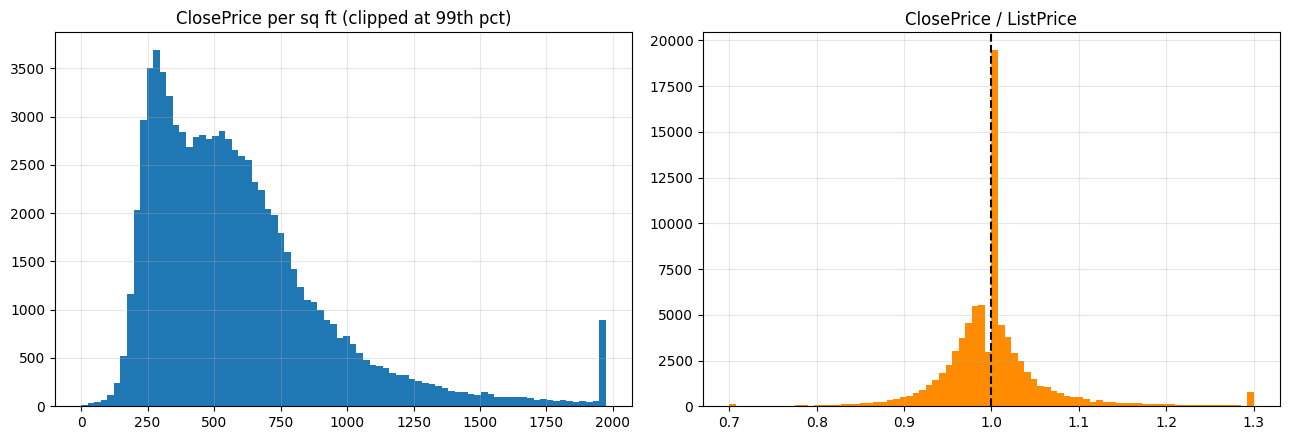

Median $/sqft: 527
Share sold above list: 38.6%


In [14]:
df["PricePerSqFt"] = df["ClosePrice"] / df["LivingArea"].where(df["LivingArea"] > 0)
df["CloseToList"] = df["ClosePrice"] / df["ListPrice"].where(df["ListPrice"] > 0)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df["PricePerSqFt"].dropna().clip(upper=df["PricePerSqFt"].quantile(.99)), bins=80)
axes[0].set_title("ClosePrice per sq ft (clipped at 99th pct)")
axes[1].hist(df["CloseToList"].dropna().clip(0.7, 1.3), bins=80, color="darkorange")
axes[1].axvline(1, color="k", ls="--"); axes[1].set_title("ClosePrice / ListPrice")
plt.tight_layout(); plt.show()
print(f"Median $/sqft: {df['PricePerSqFt'].median():,.0f}")
print(f"Share sold above list: {(df['CloseToList'] > 1).mean():.1%}")

## 11. Correlations (numeric features)

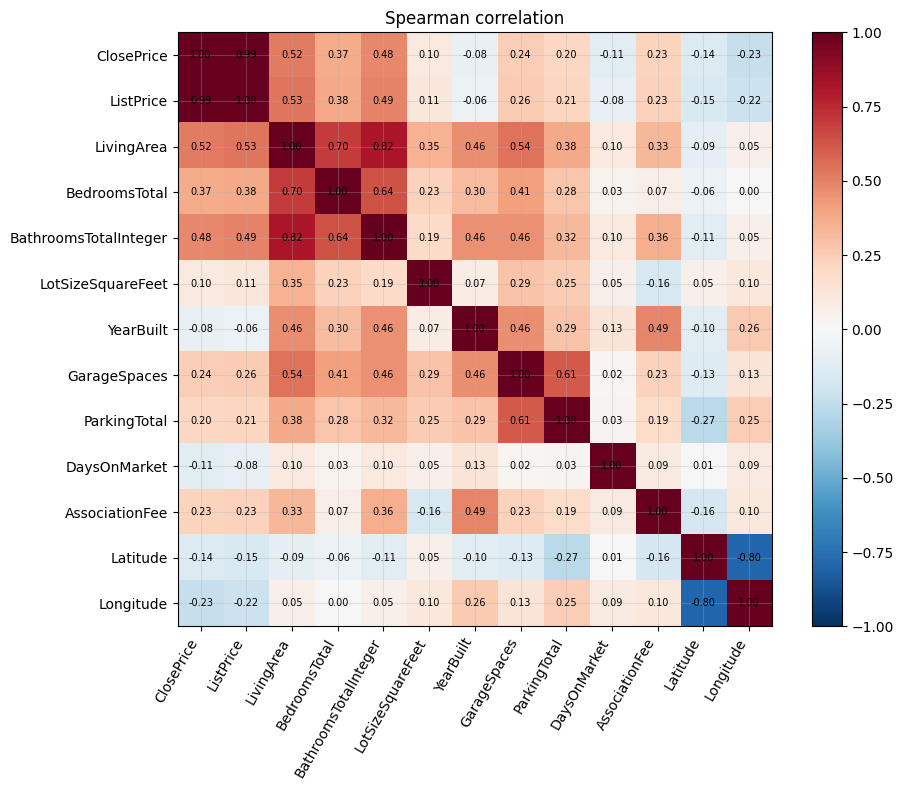

,corr w/ ClosePrice
ListPrice,0.99
LivingArea,0.52
BathroomsTotalInteger,0.48
BedroomsTotal,0.37
GarageSpaces,0.24
AssociationFee,0.23
ParkingTotal,0.20
LotSizeSquareFeet,0.10
YearBuilt,-0.08
DaysOnMarket,-0.11


In [15]:
num = ["ClosePrice", "ListPrice", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger",
       "LotSizeSquareFeet", "YearBuilt", "GarageSpaces", "ParkingTotal", "DaysOnMarket",
       "AssociationFee", "Latitude", "Longitude"]
corr = df[num].rank().corr()  # rank-then-Pearson = Spearman, no scipy needed
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num, rotation=60, ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Spearman correlation"); plt.tight_layout(); plt.show()
corr["ClosePrice"].drop("ClosePrice").sort_values(ascending=False).to_frame("corr w/ ClosePrice")